

*   جود ماجد الجودي
*  ريم بندر الاسمري


*  اسماء خالد العكبري
*  رناد محمد عبدالعزيز







In [ ]:
# Import pandas for data manipulation and analysis (DataFrames, tables)
import pandas as pd

# Import numpy for numerical operations (arrays, math functions)
import numpy as np

# Import matplotlib for basic data visualization (plots, charts)
import matplotlib.pyplot as plt

# Import seaborn for advanced and more visually appealing statistical plots
import seaborn as sns

# Import function to split dataset into training and testing sets
from sklearn.model_selection import train_test_split

# Import Linear Regression model for predicting continuous values
from sklearn.linear_model import LinearRegression

# Import evaluation metrics to measure model performance:
# mean_squared_error -> measures average squared difference between predicted and actual values
# r2_score -> measures how well the model explains the variance in the data
from sklearn.metrics import mean_squared_error, r2_score

In [ ]:
# Set a random seed to ensure reproducibility (same random values every run)
np.random.seed(42)

# Dictionary storing number of pilgrims for each Hijri year
pilgrims_by_year = {
    1436: 1952817,
    1437: 1862909,
    1438: 2352122,
    1439: 2371675,
    1440: 2489406,
    1441: 10000,
    1442: 58745,
    1443: 899353,
    1444: 1845045
}
# Initialize empty list to store generated dataset rows
data = []
# Loop through Hijri years (1436 to 1444)
for h_year in range(1436, 1445):  # 1436 → 1444
    base_pilgrims = pilgrims_by_year[h_year]
    # Loop through Hajj days (8 to 18 Dhul-Hijjah)

    for day in range(8, 19):  # 8 → 18 ذو الحجة

        # 📍 تحديد المناطق حسب اليوم
        if day == 8:
            zones = ["Makkah", "Mina"]
            event = "Tarwiyah"
        elif day == 9:
            zones = ["Arafat"]
            event = "Arafat"
        elif day == 10:
            zones = ["Muzdalifah", "Mina"]
            event = "Nahr"
        elif 11 <= day <= 13:
            zones = ["Mina"]
            event = "Tashreeq"
        else:
            zones = ["Makkah"]
            event = "Return"

        # 👥 تفويج بعد يوم 13
        if day <= 13:
            pilgrims = base_pilgrims
        else:
            reduction = 1 - ((day - 13) * 0.15)
            pilgrims = int(base_pilgrims * max(reduction, 0.2))

        for hour in range(24):
            for zone in zones:

                # 🌡️ الحرارة
                temp = np.random.uniform(38, 47)

                # ⚡ الكهرباء
                if event == "Arafat":
                    electricity = np.random.uniform(3800, 4500)
                elif event == "Nahr":
                    electricity = np.random.uniform(6000, 7200)
                elif event == "Return":
                    electricity = np.random.uniform(4500, 5200)
                else:
                    electricity = np.random.uniform(5000, 6000)

                # 👥 كثافة
                crowd_density = (pilgrims / 1_000_000) * np.random.uniform(0.8, 1.2)

                # ☀️ ضربات الشمس
                base_rate = 0.00004

                if event == "Arafat":
                    base_rate *= 2.5
                elif event == "Return":
                    base_rate *= 0.7

                heatstroke = int(pilgrims * base_rate * (temp / 40))

                # ⚡ تأثير الحرارة والكثافة
                electricity += temp * 12 + crowd_density * 15

                # 📅 التاريخ الهجري كنص
                hijri_date = f"{h_year}-12-{day}"

                data.append([
                    hijri_date,
                    h_year,
                    day,
                    hour,
                    zone,
                    pilgrims,
                    round(temp, 2),
                    round(crowd_density, 2),
                    round(electricity, 2),
                    heatstroke,
                    event
                ])

#  DataFrame
df = pd.DataFrame(data, columns=[
    "hijri_date",
    "hijri_year",
    "hajj_day",
    "hour",
    "zone",
    "pilgrims_count",
    "temperature_c",
    "crowd_density",
    "electricity_mwh",
    "heatstroke_cases",
    "event_type"
])


df['datetime_key'] = (
    df['hijri_date'] + "-" +
    df['hour'].astype(str) + "-" +
    df['zone']
)


df.to_csv("hajj_hijri_full_dataset.csv", index=False)

print(df.shape)



(2808, 12)


In [ ]:
# Display the first 10 rows of the DataFrame to preview the dataset
df.head(10)

,hijri_date,hijri_year,hajj_day,hour,zone,pilgrims_count,temperature_c,crowd_density,electricity_mwh,heatstroke_cases,event_type,datetime_key
0,1436-12-8,1436,8,0,Makkah,1952817,41.37,2.13,6479.18,80,Tarwiyah,1436-12-8-0-Makkah
1,1436-12-8,1436,8,0,Mina,1952817,43.39,1.68,5701.94,84,Tarwiyah,1436-12-8-0-Mina
2,1436-12-8,1436,8,1,Makkah,1952817,38.52,2.03,6358.93,75,Tarwiyah,1436-12-8-1-Makkah
3,1436-12-8,1436,8,1,Mina,1952817,44.37,2.32,5587.85,86,Tarwiyah,1436-12-8-1-Mina
4,1436-12-8,1436,8,2,Makkah,1952817,45.49,1.70,5783.81,88,Tarwiyah,1436-12-8-2-Makkah
5,1436-12-8,1436,8,2,Mina,1952817,39.65,1.97,5809.63,77,Tarwiyah,1436-12-8-2-Mina
6,1436-12-8,1436,8,3,Makkah,1952817,41.89,2.04,5824.48,81,Tarwiyah,1436-12-8-3-Makkah
7,1436-12-8,1436,8,3,Mina,1952817,39.26,1.85,5790.94,76,Tarwiyah,1436-12-8-3-Mina
8,1436-12-8,1436,8,4,Makkah,1952817,42.10,1.72,6316.20,82,Tarwiyah,1436-12-8-4-Makkah
9,1436-12-8,1436,8,4,Mina,1952817,42.63,1.60,6127.93,83,Tarwiyah,1436-12-8-4-Mina


In [ ]:
# Print the shape of the DataFrame (number of rows and columns)
print("Shape:", df.shape)
print()

# Display basic information about the DataFrame:
# - column names
# - data types
# - non-null values (to check for missing data)
df.info()
print()

# Show statistical summary of numerical columns:
# - mean, std, min, max, quartiles
print(df.describe())
print()

# Show summary of categorical (object) columns:
# - count, unique values, most frequent value (top), frequency
print(df.describe(include="object"))

Shape: (2808, 12)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2808 entries, 0 to 2807
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   hijri_date        2808 non-null   object 
 1   hijri_year        2808 non-null   int64  
 2   hajj_day          2808 non-null   int64  
 3   hour              2808 non-null   int64  
 4   zone              2808 non-null   object 
 5   pilgrims_count    2808 non-null   int64  
 6   temperature_c     2808 non-null   float64
 7   crowd_density     2808 non-null   float64
 8   electricity_mwh   2808 non-null   float64
 9   heatstroke_cases  2808 non-null   int64  
 10  event_type        2808 non-null   object 
 11  datetime_key      2808 non-null   object 
dtypes: float64(3), int64(5), object(4)
memory usage: 263.4+ KB

        hijri_year     hajj_day         hour  pilgrims_count  temperature_c  \
count  2808.000000  2808.000000  2808.000000    2.808000e+03    2808.000

In [ ]:
# Create a copy of the original DataFrame to preserve the raw data
# Any cleaning or modifications will be applied to 'clean_df' without affecting 'df'
clean_df = df.copy()

In [ ]:
# Convert DataFrame column names into a Python list
# Useful for quickly viewing or referencing all column names
clean_df.columns.tolist()

['hijri_date',
 'hijri_year',
 'hajj_day',
 'hour',
 'zone',
 'pilgrims_count',
 'temperature_c',
 'crowd_density',
 'electricity_mwh',
 'heatstroke_cases',
 'event_type',
 'datetime_key']

In [ ]:
# Check for missing (null) values in each column
# .isnull() creates a boolean DataFrame (True for missing values)
# .sum() counts how many missing values are in each column
clean_df.isnull().sum()

,0
hijri_date,0
hijri_year,0
hajj_day,0
hour,0
zone,0
pilgrims_count,0
temperature_c,0
crowd_density,0
electricity_mwh,0
heatstroke_cases,0


In [ ]:
# Check for duplicate rows in the DataFrame
# .duplicated() returns True for duplicated rows
# .sum() counts the total number of duplicate records
clean_df.duplicated().sum()

np.int64(0)

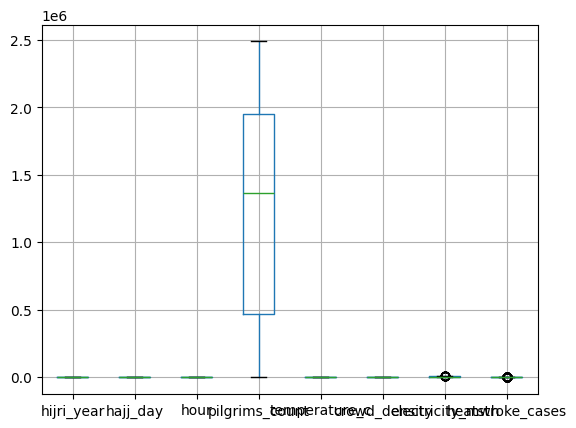

In [ ]:
# Create boxplots for all numerical columns in the DataFrame
# This helps visualize the distribution and detect potential outliers
clean_df.boxplot()

# Display the plot
plt.show()

In [ ]:
# Define a list of categorical columns to inspect
cols = ['event_type']

# Loop through each column in the list
for col in cols:
    # Print the column name
    print(f"Column: {col}")

    # Display all unique values in the column
    # Useful for understanding categories and detecting inconsistencies
    print(clean_df[col].unique())

    # Print a separator line for readability
    print("------")

Column: event_type
['Tarwiyah' 'Arafat' 'Nahr' 'Tashreeq' 'Return']
------


In [ ]:
# Display basic information about the DataFrame:
# - column names
# - data types
# - number of non-null values (helps identify missing data)
df.info()

# Generate statistical summary for numerical columns:
# - count, mean, standard deviation, min, max, and quartiles
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2808 entries, 0 to 2807
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   hijri_date        2808 non-null   object 
 1   hijri_year        2808 non-null   int64  
 2   hajj_day          2808 non-null   int64  
 3   hour              2808 non-null   int64  
 4   zone              2808 non-null   object 
 5   pilgrims_count    2808 non-null   int64  
 6   temperature_c     2808 non-null   float64
 7   crowd_density     2808 non-null   float64
 8   electricity_mwh   2808 non-null   float64
 9   heatstroke_cases  2808 non-null   int64  
 10  event_type        2808 non-null   object 
 11  datetime_key      2808 non-null   object 
dtypes: float64(3), int64(5), object(4)
memory usage: 263.4+ KB


,hijri_year,hajj_day,hour,pilgrims_count,temperature_c,crowd_density,electricity_mwh,heatstroke_cases
count,2808.000000,2808.000000,2808.000000,2.808000e+03,2808.000000,2808.000000,2808.000000,2808.000000
mean,1440.000000,12.384615,11.500000,1.271814e+06,42.538757,1.266717,5836.701293,57.054131
std,2.582449,3.271397,6.923419,8.855875e+05,2.564431,0.899000,728.793264,54.936093
min,1436.000000,8.000000,0.000000,2.500000e+03,38.000000,0.000000,4279.560000,0.000000
25%,1438.000000,10.000000,5.750000,4.657270e+05,40.310000,0.440000,5327.557500,13.000000
50%,1440.000000,12.000000,11.500000,1.366971e+06,42.590000,1.390000,5677.245000,42.000000
75%,1442.000000,15.000000,17.250000,1.952817e+06,44.790000,2.060000,6267.695000,88.000000
max,1444.000000,18.000000,23.000000,2.489406e+06,47.000000,2.990000,7777.220000,291.000000


In [ ]:
# Heatstroke cases vary across Hajj days, showing peak risk periods.
# Weak correlation: temperature alone has limited impact on heatstroke cases.
# Electricity usage changes by Hajj day, indicating varying demand.
# Pilgrims count varies across days and drives resource demand.
# Strong link between pilgrims and heatstroke; temperature impact is weaker.



# تختلف حالات الإجهاد الحراري عبر أيام الحج، مما يوضح فترات الخطر الأعلى.
# الارتباط ضعيف: درجة الحرارة وحدها تأثيرها محدود على حالات الإجهاد الحراري.
# يتغير استهلاك الكهرباء حسب يوم الحج، مما يدل على اختلاف الطلب.
# يختلف عدد الحجاج عبر الأيام ويؤثر على الطلب على الموارد.
# هناك علاقة قوية بين عدد الحجاج وحالات الإجهاد الحراري، وتأثير الحرارة أضعف.

heat_by_day = df.groupby('hajj_day')['heatstroke_cases'].mean()

plt.figure()
heat_by_day.plot(kind='line')
plt.title("Heatstroke Cases by Hajj Day")
plt.xlabel("Hajj Day")
plt.ylabel("Average Heatstroke Cases")
plt.grid()
plt.show()

print(heat_by_day)

In [ ]:
# Moderate relationship between temperature and electricity usage.
print(correlation)

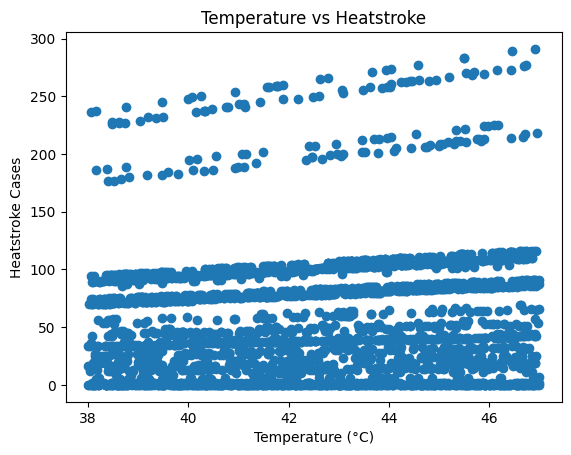

                  temperature_c  heatstroke_cases
temperature_c          1.000000          0.073878
heatstroke_cases       0.073878          1.000000


In [ ]:
# Create a new figure for the plot
plt.figure()

# Create a scatter plot showing the relationship between temperature and heatstroke cases
plt.scatter(df['temperature_c'], df['heatstroke_cases'])

# Set the title of the plot
plt.title("Temperature vs Heatstroke")

# Label the x-axis (temperature in Celsius)
plt.xlabel("Temperature (°C)")

# Label the y-axis (number of heatstroke cases)
plt.ylabel("Heatstroke Cases")

# Display the plot
plt.show()

# correlation
corr_temp_heat = df[['temperature_c','heatstroke_cases']].corr()
print(corr_temp_heat)

In [ ]:
# Select temperature and electricity columns and compute their correlation matrix
# .corr() calculates the Pearson correlation coefficient between the variables
corr_energy = df[['temperature_c', 'electricity_mwh']].corr()

# Print the correlation result to see the strength and direction of the relationship
print(corr_energy)

                 temperature_c  electricity_mwh
temperature_c         1.000000         0.043993
electricity_mwh       0.043993         1.000000


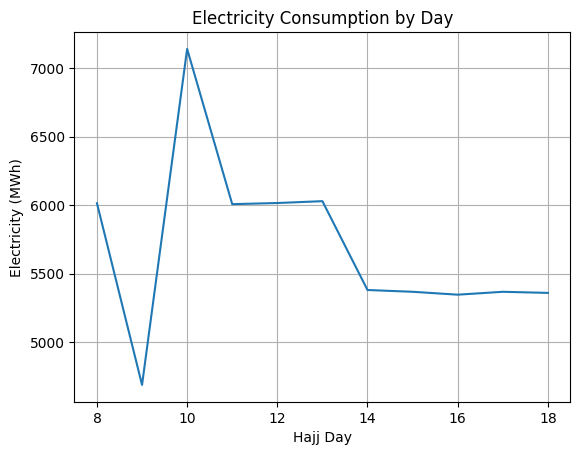

hajj_day
8     6014.432199
9     4689.582037
10    7139.400162
11    6007.588981
12    6015.839398
13    6029.334722
14    5381.648843
15    5368.649537
16    5347.553796
17    5368.624491
18    5360.630278
Name: electricity_mwh, dtype: float64


In [ ]:
# Group the data by Hajj day and calculate the average electricity consumption for each day
electricity_day = df.groupby('hajj_day')['electricity_mwh'].mean()

# Create a new figure for the line plot
plt.figure()

# Plot the average electricity consumption as a line chart
electricity_day.plot(kind='line')

# Set the title of the plot
plt.title("Electricity Consumption by Day")

# Label the x-axis (Hajj days)
plt.xlabel("Hajj Day")

# Label the y-axis (Electricity consumption in MWh)
plt.ylabel("Electricity (MWh)")

# Add grid lines for better readability
plt.grid()

# Display the plot
plt.show()

# Print the calculated average electricity consumption per day
print(electricity_day)

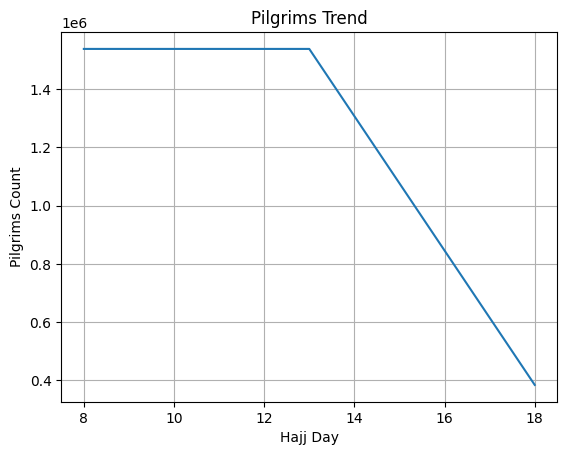

hajj_day
8     1.538008e+06
9     1.538008e+06
10    1.538008e+06
11    1.538008e+06
12    1.538008e+06
13    1.538008e+06
14    1.307306e+06
15    1.076605e+06
16    8.459040e+05
17    6.152029e+05
18    3.845017e+05
Name: pilgrims_count, dtype: float64


In [ ]:
# Group the data by Hajj day and calculate the average number of pilgrims per day
# تجميع البيانات حسب يوم الحج وحساب متوسط عدد الحجاج لكل يوم
pilgrims_day = df.groupby('hajj_day')['pilgrims_count'].mean()

# Create a new figure for the plot
plt.figure()

# Plot the pilgrims trend as a line chart to show variation across Hajj days
# رسم خط يوضح تغير عدد الحجاج عبر أيام الحج
pilgrims_day.plot(kind='line')

# Set the title of the plot
plt.title("Pilgrims Trend")

# Label the x-axis (Hajj days)
plt.xlabel("Hajj Day")

# Label the y-axis (number of pilgrims)
plt.ylabel("Pilgrims Count")

# Add grid for better visualization
plt.grid()

# Display the plot
plt.show()

# Print the calculated average pilgrims per day
print(pilgrims_day)

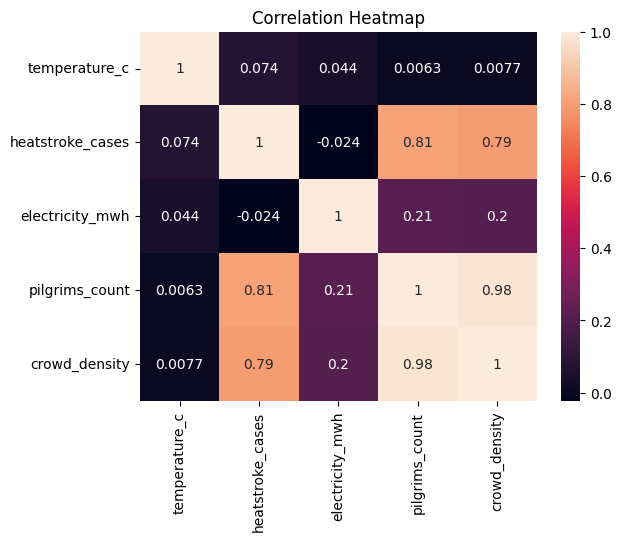

In [ ]:
# Create a new figure for the heatmap
plt.figure()

# Compute correlation between selected numerical variables:
# temperature, heatstroke cases, electricity, pilgrims count, and crowd density
# Then visualize it using a heatmap with annotated correlation values
sns.heatmap(
    df[['temperature_c', 'heatstroke_cases', 'electricity_mwh', 'pilgrims_count', 'crowd_density']].corr(),
    annot=True  # display correlation values inside the cells
)

# Set the title of the heatmap
plt.title("Correlation Heatmap")

# Display the plot
plt.show()

In [ ]:
# Sort the DataFrame by heatstroke_cases in descending order
# This brings the highest-risk records (most heatstroke cases) to the top
top_risk = df.sort_values(by='heatstroke_cases', ascending=False).head(10)

# Display the top 10 records with the highest heatstroke cases
top_risk

,hijri_date,hijri_year,hajj_day,hour,zone,pilgrims_count,temperature_c,crowd_density,electricity_mwh,heatstroke_cases,event_type,datetime_key
1308,1440-12-9,1440,9,12,Arafat,2489406,46.91,2.59,4419.88,291,Arafat,1440-12-9-12-Arafat
1310,1440-12-9,1440,9,14,Arafat,2489406,46.45,2.61,4523.36,289,Arafat,1440-12-9-14-Arafat
1317,1440-12-9,1440,9,21,Arafat,2489406,45.51,2.13,5060.35,283,Arafat,1440-12-9-21-Arafat
1299,1440-12-9,1440,9,3,Arafat,2489406,45.50,2.83,4766.65,283,Arafat,1440-12-9-3-Arafat
1298,1440-12-9,1440,9,2,Arafat,2489406,44.58,2.14,4944.19,277,Arafat,1440-12-9-2-Arafat
993,1439-12-9,1439,9,9,Arafat,2371675,46.73,2.12,4698.95,277,Arafat,1439-12-9-9-Arafat
995,1439-12-9,1439,9,11,Arafat,2371675,46.70,2.38,4432.25,276,Arafat,1439-12-9-11-Arafat
1306,1440-12-9,1440,9,10,Arafat,2489406,44.04,2.93,4936.29,274,Arafat,1440-12-9-10-Arafat
674,1438-12-9,1438,9,2,Arafat,2352122,46.43,2.28,4427.89,273,Arafat,1438-12-9-2-Arafat
1309,1440-12-9,1440,9,13,Arafat,2489406,43.94,2.11,4840.53,273,Arafat,1440-12-9-13-Arafat


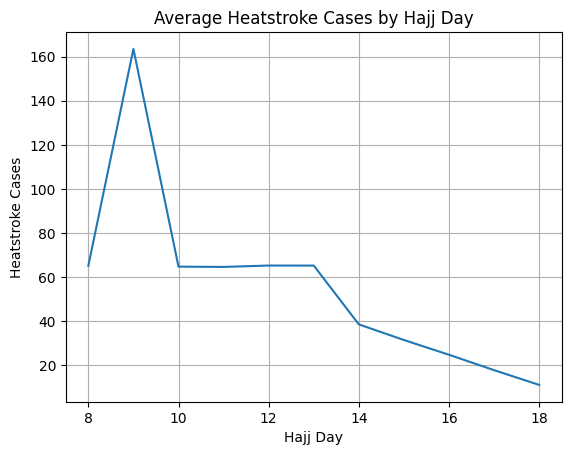

,heatstroke_cases
hajj_day,
8,65.115741
9,163.509259
10,64.719907
11,64.601852
12,65.222222
13,65.203704
14,38.518519
15,31.435185
16,24.736111


In [ ]:
# Group the data by Hajj day and calculate the average number of heatstroke cases per day
heat_by_day = df.groupby('hajj_day')['heatstroke_cases'].mean()

# Create a new figure for the plot
plt.figure()

# Plot the average heatstroke cases as a line chart
heat_by_day.plot()

# Set the title of the plot
plt.title("Average Heatstroke Cases by Hajj Day")

# Label the x-axis (Hajj days)
plt.xlabel("Hajj Day")

# Label the y-axis (heatstroke cases)
plt.ylabel("Heatstroke Cases")

# Add grid lines for better readability
plt.grid()

# Display the plot
plt.show()

# Display the calculated averages
heat_by_day

In [ ]:
# Heatstroke cases vary by hour, showing critical time periods.
# تختلف حالات الإجهاد الحراري حسب الساعة، مما يوضح أوقات الخطر.

hour_heat = df.groupby('hour')['heatstroke_cases'].mean()

plt.figure()
hour_heat.plot()
plt.title("Heatstroke by Hour")
plt.xlabel("Hour")
plt.ylabel("Cases")
plt.grid()
plt.show()

In [ ]:
df = clean_df.copy()
# 🧠 Feature Engineering
# =========================

# 🔥 تحويل event_type إلى أرقام
df = pd.get_dummies(df, columns=["event_type"], drop_first=True)

# ⏱️ cyclic time (الساعة لها نمط دائري)
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)
df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

# 🌡️ تأثير غير خطي للحرارة
df['temp_squared'] = df['temperature_c'] ** 2

# 🔥 تفاعل بين الحرارة والكثافة
df['temp_x_density'] = df['temperature_c'] * df['crowd_density']

# 🔥 حرارة خطرة
df['extreme_heat'] = (df['temperature_c'] > 42).astype(int)

# 🧊 Lag features (المفتاح الحقيقي للتنبؤ)
df['lag_1'] = df['electricity_mwh'].shift(1)
df['lag_2'] = df['electricity_mwh'].shift(2)
df['lag_24'] = df['electricity_mwh'].shift(24)
df['lag_48'] = df['electricity_mwh'].shift(48)

# 📉 Rolling statistics (يعطي سلوك عام)
df['rolling_mean_6'] = df['electricity_mwh'].rolling(6).mean()
df['rolling_std_6'] = df['electricity_mwh'].rolling(6).std()

# حذف القيم الفارغة الناتجة من lag
df = df.dropna()

In [ ]:
# 🎯 Features & Target
# =========================

features = [
    'temperature_c','temp_squared','temp_x_density',
    'crowd_density','pilgrims_count','heatstroke_cases',
    'extreme_heat','hour','hajj_day',
    'hour_sin','hour_cos',
    'lag_1','lag_2','lag_24','lag_48',
    'rolling_mean_6','rolling_std_6'
] + [col for col in df.columns if 'event_type_' in col]

X = df[features]
y = df['electricity_mwh']


In [ ]:
#  Time Split
# =========================

train = df[df['hijri_year'] < 1444]
test = df[df['hijri_year'] == 1444]

X_train = train[features]
y_train = train['electricity_mwh']

X_test = test[features]
y_test = test['electricity_mwh']

In [ ]:

from sklearn.model_selection import train_test_split
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# Use all numeric columns except target
target = 'electricity_mwh'

features = df.select_dtypes(include='number').columns.tolist()
features.remove(target)

X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = LGBMRegressor(
    n_estimators=1500,
    learning_rate=0.01,
    max_depth=7,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1
)

model.fit(X_train, y_train)

preds = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, preds))
r2 = r2_score(y_test, preds)

print("RMSE:", rmse)
print("R2:", r2)

RMSE: 242.86661859902262
R2: 0.8927854034403293


In [ ]:
#
# =========================

pred_lgbm = lgbm.predict(X_test)
pred_xgb = xgb.predict(X_test)

# دمج متوسط
preds = (pred_lgbm + pred_xgb) / 2



In [ ]:
# 📊 Feature Importance
# =========================

plt.figure(figsize=(8,6))
plt.barh(features, lgbm.feature_importances_)
plt.title("Feature Importance")
plt.show()

In [ ]:
#  Forecast 1445
# =========================

future = df[df['hijri_year'] == 1444].copy()
future['hijri_year'] = 1445

predictions = []

for i in range(len(future)):
    row = future.iloc[i:i+1].copy()

    # تحديث lag باستخدام التوقعات السابقة
    if i > 0:
        row['lag_1'] = predictions[-1]

    pred = lgbm.predict(row[features])[0]
    predictions.append(pred)

print("Future predictions generated!")

MSE: 53067.35570604156


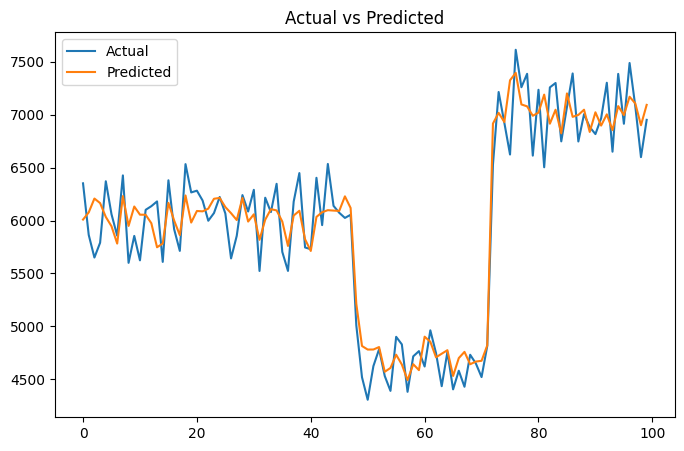

In [ ]:
# The model predicts heat-related patterns based on multiple factors.
# النموذج يتنبأ بالأنماط المرتبطة بالحرارة بناءً على عدة عوامل.
from sklearn.metrics import mean_squared_error
mse = mean_squared_error(y_test, preds)
print("MSE:", mse)

plt.figure(figsize=(8,5))
plt.plot(y_test.values[:100], label='Actual')
plt.plot(preds[:100], label='Predicted')
plt.legend()
plt.title("Actual vs Predicted")
plt.show()


In [ ]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# =========================
# 1. Classification
# =========================

# Create demand categories
def classify_demand(x):
    if x < 3000:
        return "Low"
    elif x < 6000:
        return "Medium"
    else:
        return "High"

df['demand_level'] = df['electricity_mwh'].apply(classify_demand)

# Select features
features = [
    'temperature_c',
    'pilgrims_count',
    'crowd_density',
    'hour',
    'hajj_day'
]

X = df[features]
y = df['demand_level']

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Train model
model_cls = RandomForestClassifier(n_estimators=100, random_state=42)
model_cls.fit(X_train, y_train)

# Predict
preds_cls = model_cls.predict(X_test)

# Evaluate
accuracy = accuracy_score(y_test, preds_cls)
print("Classification Accuracy:", accuracy)

print("\nClassification Report:")
print(classification_report(y_test, preds_cls))



Classification Accuracy: 0.8333333333333334

Classification Report:
              precision    recall  f1-score   support

        High       0.77      0.76      0.76       194
      Medium       0.87      0.87      0.87       358

    accuracy                           0.83       552
   macro avg       0.82      0.82      0.82       552
weighted avg       0.83      0.83      0.83       552



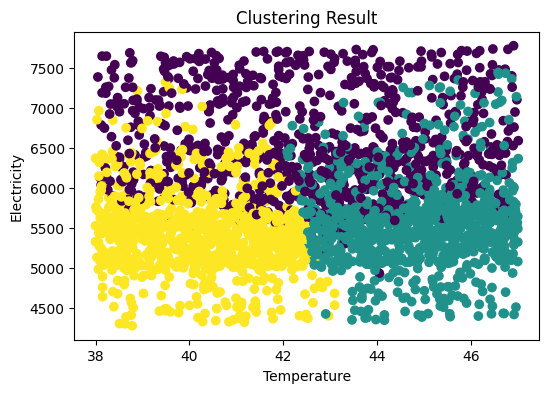

In [ ]:

# 2. Clustering
# =========================

# Select clustering features
features_cluster = df[['temperature_c', 'electricity_mwh', 'crowd_density']]

# Scale data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features_cluster)

# Apply KMeans
kmeans = KMeans(n_clusters=3, random_state=42)
df['cluster'] = kmeans.fit_predict(X_scaled)

# Plot clustering
plt.figure(figsize=(6,4))
plt.scatter(df['temperature_c'], df['electricity_mwh'], c=df['cluster'])
plt.xlabel("Temperature")
plt.ylabel("Electricity")
plt.title("Clustering Result")
plt.show()



# Classification Accuracy shows how well the model predicts demand levels.
# توضح دقة التصنيف مدى قدرة النموذج على التنبؤ بمستوى الطلب.

# Clustering groups similar patterns such as high heat with high electricity usage.
# يقوم التجميع بتقسيم الأنماط المتشابهة مثل الحرارة العالية مع استهلاك الكهرباء المرتفع.

# اللون الموف يوضح الاستهلاك وضغط العالي
# الاصفر استهلاك متوسط
#الاخضر استهلاك اقل - ايام هادئة

In [ ]:
df.to_csv("final_data.csv", index=False)
